In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
from google.colab import drive
drive.mount('/content/drive')

BASE = '/content/drive/MyDrive/imdb-sentiment-rnn'
for f in ['data', 'models', 'outputs', 'notebooks']:
    os.makedirs(f'{BASE}/{f}', exist_ok=True)
print("Folders ready:", BASE)

Mounted at /content/drive
Folders ready: /content/drive/MyDrive/imdb-sentiment-rnn


In [3]:
df = pd.read_csv(f'{BASE}/data/IMDB Dataset.csv')
print("Shape:", df.shape)
df.head()

Shape: (50000, 2)


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [4]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate reviews:", df.duplicated(subset=['review']).sum())
print()
print(df['sentiment'].value_counts())

Missing values: 0
Duplicate reviews: 418

sentiment
positive    25000
negative    25000
Name: count, dtype: int64


In [5]:
df = df.drop_duplicates(subset=['review']).reset_index(drop=True)
df['label'] = df['sentiment'].map({'positive': 1, 'negative': 0})

print("Shape after cleaning:", df.shape)
print(df['label'].value_counts())

Shape after cleaning: (49582, 3)
label
1    24884
0    24698
Name: count, dtype: int64


In [6]:
df = df.drop_duplicates(subset=['review']).reset_index(drop=True)
df['label'] = df['sentiment'].map({'positive': 1, 'negative': 0})

print("Shape after cleaning:", df.shape)
print(df['label'].value_counts())

Shape after cleaning: (49582, 3)
label
1    24884
0    24698
Name: count, dtype: int64


count    49582.000000
mean       231.350167
std        171.542020
min          4.000000
25%        126.000000
50%        173.000000
75%        281.000000
max       2470.000000
Name: word_count, dtype: float64


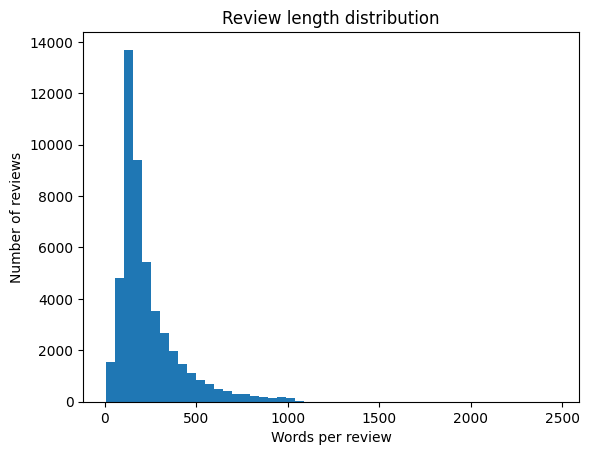

In [7]:
df['word_count'] = df['review'].apply(lambda x: len(x.split()))
print(df['word_count'].describe())

plt.hist(df['word_count'], bins=50)
plt.xlabel('Words per review')
plt.ylabel('Number of reviews')
plt.title('Review length distribution')
plt.savefig(f'{BASE}/outputs/review_length.png')
plt.show()

In [8]:
df.to_csv(f'{BASE}/data/imdb_clean.csv', index=False)
print("Saved.")

Saved.


In [2]:
import re, json, os
import pandas as pd
import torch
from collections import Counter
from sklearn.model_selection import train_test_split
from google.colab import drive

drive.mount('/content/drive')
BASE = '/content/drive/MyDrive/imdb-sentiment-rnn'

df = pd.read_csv(f'{BASE}/data/imdb_clean.csv')
print(df.shape)

Mounted at /content/drive
(49582, 4)


In [3]:
def clean_text(text):
    text = re.sub(r'<.*?>', ' ', text)       # remove HTML tags like <br />
    text = text.lower()
    text = re.sub(r"[^a-z' ]", ' ', text)    # keep only letters and apostrophes
    return text.split()

df['tokens'] = df['review'].apply(clean_text)
print(df['tokens'][0][:20])

['one', 'of', 'the', 'other', 'reviewers', 'has', 'mentioned', 'that', 'after', 'watching', 'just', 'oz', 'episode', "you'll", 'be', 'hooked', 'they', 'are', 'right', 'as']


In [4]:
train_df, temp_df = train_test_split(df, test_size=0.30, random_state=42, stratify=df['label'])
val_df, test_df = train_test_split(temp_df, test_size=0.50, random_state=42, stratify=temp_df['label'])

print("Train:", len(train_df), "Val:", len(val_df), "Test:", len(test_df))

Train: 34707 Val: 7437 Test: 7438


In [5]:
MAX_VOCAB = 20000
counter = Counter(word for tokens in train_df['tokens'] for word in tokens)

vocab = {'<PAD>': 0, '<UNK>': 1}
for word, _ in counter.most_common(MAX_VOCAB - 2):
    vocab[word] = len(vocab)

print("Vocab size:", len(vocab))

Vocab size: 20000


In [6]:
MAX_LEN = 300

def encode(tokens):
    ids = [vocab.get(w, 1) for w in tokens][:MAX_LEN]   # words -> numbers, cut at 300
    return [0] * (MAX_LEN - len(ids)) + ids              # pad at the start

def make_tensors(d):
    X = torch.tensor([encode(t) for t in d['tokens']], dtype=torch.long)
    y = torch.tensor(d['label'].values, dtype=torch.float32)
    return X, y

X_train, y_train = make_tensors(train_df)
X_val, y_val = make_tensors(val_df)
X_test, y_test = make_tensors(test_df)

print(X_train.shape, X_val.shape, X_test.shape)
print("Example:", X_train[0][-15:])

torch.Size([34707, 300]) torch.Size([7437, 300]) torch.Size([7438, 300])
Example: tensor([  310,    16,  8315,     3, 11620,    18,   196,    43,     9,     2,
          237,   205,    13,    72,   126])


In [7]:
cut = (train_df['tokens'].apply(len) > MAX_LEN).mean() * 100
print(f"Reviews longer than {MAX_LEN} words: {cut:.1f}%")

Reviews longer than 300 words: 22.1%


In [8]:
torch.save({'X_train': X_train, 'y_train': y_train,
            'X_val': X_val, 'y_val': y_val,
            'X_test': X_test, 'y_test': y_test},
           f'{BASE}/data/tensors.pt')

with open(f'{BASE}/data/vocab.json', 'w') as f:
    json.dump(vocab, f)
print("Saved.")

Saved.


In [9]:
import torch, json
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from google.colab import drive

drive.mount('/content/drive')
BASE = '/content/drive/MyDrive/imdb-sentiment-rnn'

data = torch.load(f'{BASE}/data/tensors.pt')
X_train, y_train = data['X_train'], data['y_train']
X_val, y_val = data['X_val'], data['y_val']
X_test, y_test = data['X_test'], data['y_test']

with open(f'{BASE}/data/vocab.json') as f:
    vocab = json.load(f)
VOCAB_SIZE = len(vocab)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device:", device, "| Vocab size:", VOCAB_SIZE)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda | Vocab size: 20000


In [10]:
BATCH_SIZE = 64

train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=BATCH_SIZE)
test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=BATCH_SIZE)

print("Batches:", len(train_loader), len(val_loader), len(test_loader))

Batches: 543 117 117


In [11]:
class SimpleRNN(nn.Module):
    def __init__(self, vocab_size, embed_dim=128, hidden_dim=128):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.rnn = nn.RNN(embed_dim, hidden_dim, batch_first=True)
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        emb = self.embedding(x)           # (batch, 300, 128)
        _, h = self.rnn(emb)              # h = final memory after reading the review
        out = self.dropout(h[-1])         # (batch, 128)
        return self.fc(out).squeeze(1)    # (batch,) one score per review

model = SimpleRNN(VOCAB_SIZE).to(device)
print(model)

SimpleRNN(
  (embedding): Embedding(20000, 128, padding_idx=0)
  (rnn): RNN(128, 128, batch_first=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=128, out_features=1, bias=True)
)


In [12]:
xb, yb = next(iter(train_loader))
xb, yb = xb.to(device), yb.to(device)

with torch.no_grad():
    out = model(xb)

print("Input batch:", xb.shape)
print("Output:", out.shape)

total = sum(p.numel() for p in model.parameters())
print(f"Total parameters: {total:,}")

Input batch: torch.Size([64, 300])
Output: torch.Size([64])
Total parameters: 2,593,153


In [13]:
import torch.optim as optim
import matplotlib.pyplot as plt

model = SimpleRNN(VOCAB_SIZE).to(device)   # fresh model
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    total_loss, correct, n = 0, 0, 0
    with torch.set_grad_enabled(train):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            loss = criterion(out, yb)
            if train:
                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
            total_loss += loss.item() * len(yb)
            correct += ((out > 0).float() == yb).sum().item()
            n += len(yb)
    return total_loss / n, correct / n

In [14]:
EPOCHS = 10
history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
best_val_acc = 0

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = run_epoch(train_loader, train=True)
    va_loss, va_acc = run_epoch(val_loader, train=False)

    history['train_loss'].append(tr_loss)
    history['val_loss'].append(va_loss)
    history['train_acc'].append(tr_acc)
    history['val_acc'].append(va_acc)

    if va_acc > best_val_acc:
        best_val_acc = va_acc
        torch.save(model.state_dict(), f'{BASE}/models/baseline_rnn.pth')

    print(f"Epoch {epoch:2d} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | val loss {va_loss:.4f} acc {va_acc:.4f}")

print("\nBest validation accuracy:", round(best_val_acc, 4))

Epoch  1 | train loss 0.6537 acc 0.6121 | val loss 0.6483 acc 0.6293
Epoch  2 | train loss 0.5609 acc 0.7267 | val loss 0.5599 acc 0.7320
Epoch  3 | train loss 0.5134 acc 0.7654 | val loss 0.5468 acc 0.7422
Epoch  4 | train loss 0.4688 acc 0.7932 | val loss 0.5220 acc 0.7681
Epoch  5 | train loss 0.4272 acc 0.8171 | val loss 0.5048 acc 0.7878
Epoch  6 | train loss 0.3850 acc 0.8415 | val loss 0.5218 acc 0.7515
Epoch  7 | train loss 0.3520 acc 0.8554 | val loss 0.4971 acc 0.7975
Epoch  8 | train loss 0.3235 acc 0.8718 | val loss 0.4806 acc 0.8122
Epoch  9 | train loss 0.2922 acc 0.8862 | val loss 0.4924 acc 0.7874
Epoch 10 | train loss 0.2603 acc 0.9024 | val loss 0.5357 acc 0.7982

Best validation accuracy: 0.8122


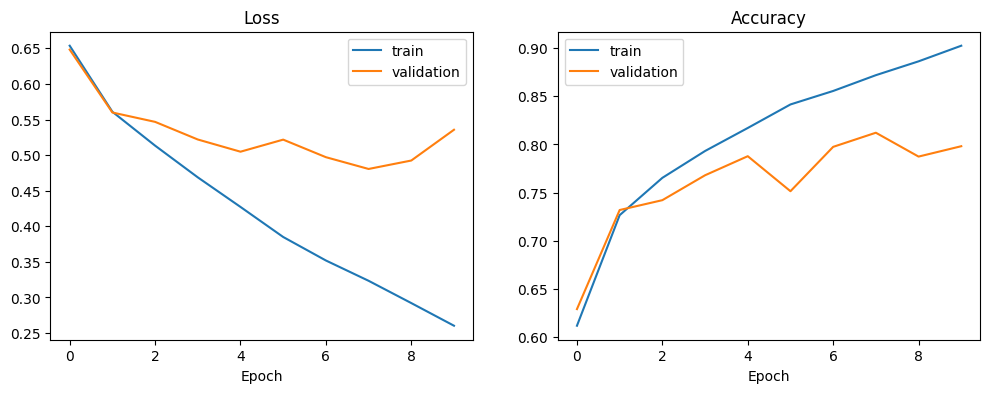

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(history['train_loss'], label='train')
ax[0].plot(history['val_loss'], label='validation')
ax[0].set_title('Loss'); ax[0].set_xlabel('Epoch'); ax[0].legend()

ax[1].plot(history['train_acc'], label='train')
ax[1].plot(history['val_acc'], label='validation')
ax[1].set_title('Accuracy'); ax[1].set_xlabel('Epoch'); ax[1].legend()

plt.savefig(f'{BASE}/outputs/baseline_rnn_curves.png')
plt.show()

In [16]:
model = SimpleRNN(VOCAB_SIZE).to(device)
model.load_state_dict(torch.load(f'{BASE}/models/baseline_rnn.pth'))
model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for xb, yb in test_loader:
        out = model(xb.to(device))
        all_preds.extend((out > 0).int().cpu().tolist())
        all_labels.extend(yb.int().tolist())

print("Reviews tested:", len(all_preds))

Reviews tested: 7438


In [17]:
from sklearn.metrics import accuracy_score, classification_report, f1_score

print("Test accuracy:", round(accuracy_score(all_labels, all_preds), 4))
print("Macro F1:", round(f1_score(all_labels, all_preds, average='macro'), 4))
print()
print(classification_report(all_labels, all_preds, target_names=['negative', 'positive']))

Test accuracy: 0.7978
Macro F1: 0.7978

              precision    recall  f1-score   support

    negative       0.80      0.79      0.80      3705
    positive       0.79      0.81      0.80      3733

    accuracy                           0.80      7438
   macro avg       0.80      0.80      0.80      7438
weighted avg       0.80      0.80      0.80      7438



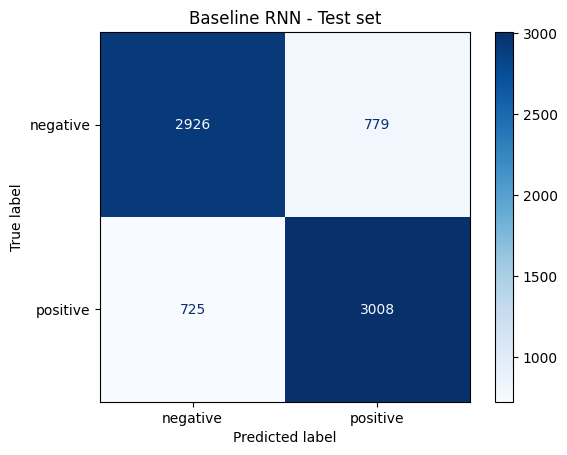

In [18]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    all_labels, all_preds, display_labels=['negative', 'positive'], cmap='Blues')
plt.title('Baseline RNN - Test set')
plt.savefig(f'{BASE}/outputs/baseline_rnn_confusion.png')
plt.show()

In [19]:
inv_vocab = {i: w for w, i in vocab.items()}
names = ['negative', 'positive']

wrong = [i for i, (p, l) in enumerate(zip(all_preds, all_labels)) if p != l]
print("Total wrong:", len(wrong))

for i in wrong[:4]:
    words = [inv_vocab[t] for t in X_test[i].tolist() if t != 0]
    print(f"\nTrue: {names[all_labels[i]]} | Predicted: {names[all_preds[i]]}")
    print(" ".join(words[:60]), "...")

Total wrong: 1504

True: positive | Predicted: negative
im a die hard dads army fan and nothing will ever change that i got all the tapes dvd's and <UNK> and every time i watch listen to them its brand new the film the film is a re run of certain episodes man and the hour enemy within the gates battle school and numerous others with a different edge ...

True: positive | Predicted: negative
i liked this movie it was pretty cool it has it all cars gun shooting fighting and even a token girl it does not excel in any of this things with the exception of the cars a bit of shooting a bit of fighting a bit of <UNK> around and lot s of car with a great chase near the ...

True: negative | Predicted: positive
no doubt frank sinatra was a talented actor as well as a talented singer after all very few actors nowadays can get a scene just right in one take and that was pretty much sinatra's <UNK> <UNK> on set i feel that as the 's wore on the quality of the man's films really started to tank the 

In [20]:
import torch.optim as optim

class SeqModel(nn.Module):
    def __init__(self, vocab_size, rnn_type='lstm', embed_dim=128, hidden_dim=128):
        super().__init__()
        self.rnn_type = rnn_type
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        rnn_cls = nn.LSTM if rnn_type == 'lstm' else nn.GRU
        self.rnn = rnn_cls(embed_dim, hidden_dim, batch_first=True)
        self.dropout = nn.Dropout(0.4)
        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        emb = self.embedding(x)
        _, h = self.rnn(emb)
        if self.rnn_type == 'lstm':
            h = h[0]                  # LSTM returns (hidden, cell); we need hidden
        return self.fc(self.dropout(h[-1])).squeeze(1)

In [21]:
criterion = nn.BCEWithLogitsLoss()

def run_epoch(model, loader, optimizer=None):
    train = optimizer is not None
    model.train() if train else model.eval()
    total_loss, correct, n = 0, 0, 0
    with torch.set_grad_enabled(train):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            loss = criterion(out, yb)
            if train:
                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
            total_loss += loss.item() * len(yb)
            correct += ((out > 0).float() == yb).sum().item()
            n += len(yb)
    return total_loss / n, correct / n

def train_model(rnn_type, epochs=8):
    model = SeqModel(VOCAB_SIZE, rnn_type).to(device)
    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    hist = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    best = 0
    print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")

    for epoch in range(1, epochs + 1):
        tr_loss, tr_acc = run_epoch(model, train_loader, optimizer)
        va_loss, va_acc = run_epoch(model, val_loader)
        for k, v in zip(hist, [tr_loss, va_loss, tr_acc, va_acc]):
            hist[k].append(v)
        if va_acc > best:
            best = va_acc
            torch.save(model.state_dict(), f'{BASE}/models/{rnn_type}.pth')
        print(f"Epoch {epoch:2d} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | val loss {va_loss:.4f} acc {va_acc:.4f}")

    print(f"\nBest validation accuracy ({rnn_type}):", round(best, 4))
    return hist, best

In [22]:
hist_lstm, best_lstm = train_model('lstm')

Parameters: 2,692,225
Epoch  1 | train loss 0.5835 acc 0.6900 | val loss 0.5050 acc 0.7611
Epoch  2 | train loss 0.4314 acc 0.8146 | val loss 0.4139 acc 0.8170
Epoch  3 | train loss 0.3360 acc 0.8663 | val loss 0.3725 acc 0.8294
Epoch  4 | train loss 0.2584 acc 0.9014 | val loss 0.3545 acc 0.8518
Epoch  5 | train loss 0.2038 acc 0.9241 | val loss 0.3152 acc 0.8743
Epoch  6 | train loss 0.1628 acc 0.9410 | val loss 0.3363 acc 0.8813
Epoch  7 | train loss 0.1259 acc 0.9576 | val loss 0.3648 acc 0.8704
Epoch  8 | train loss 0.0926 acc 0.9692 | val loss 0.4330 acc 0.8834

Best validation accuracy (lstm): 0.8834


In [23]:
hist_gru, best_gru = train_model('gru')

Parameters: 2,659,201
Epoch  1 | train loss 0.5903 acc 0.6816 | val loss 0.4753 acc 0.7892
Epoch  2 | train loss 0.3528 acc 0.8514 | val loss 0.3035 acc 0.8762
Epoch  3 | train loss 0.2344 acc 0.9074 | val loss 0.2822 acc 0.8838
Epoch  4 | train loss 0.1660 acc 0.9390 | val loss 0.2797 acc 0.8891
Epoch  5 | train loss 0.1092 acc 0.9629 | val loss 0.3389 acc 0.8892
Epoch  6 | train loss 0.0645 acc 0.9795 | val loss 0.4149 acc 0.8876
Epoch  7 | train loss 0.0386 acc 0.9888 | val loss 0.5168 acc 0.8822
Epoch  8 | train loss 0.0236 acc 0.9927 | val loss 0.5810 acc 0.8818

Best validation accuracy (gru): 0.8892


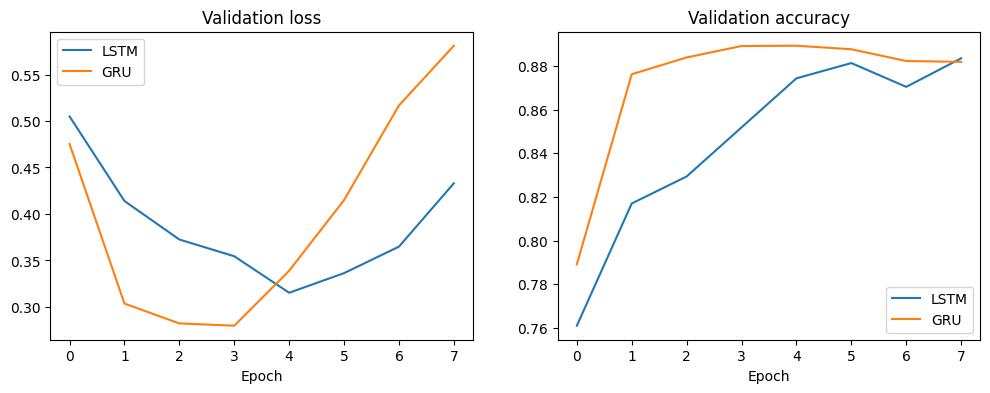

In [24]:
import json
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name, h in [('LSTM', hist_lstm), ('GRU', hist_gru)]:
    ax[0].plot(h['val_loss'], label=name)
    ax[1].plot(h['val_acc'], label=name)
ax[0].set_title('Validation loss'); ax[0].set_xlabel('Epoch'); ax[0].legend()
ax[1].set_title('Validation accuracy'); ax[1].set_xlabel('Epoch'); ax[1].legend()
plt.savefig(f'{BASE}/outputs/lstm_gru_curves.png')
plt.show()

with open(f'{BASE}/outputs/lstm_gru_history.json', 'w') as f:
    json.dump({'lstm': hist_lstm, 'gru': hist_gru}, f)

In [25]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

def predict(model):
    model.eval()
    preds, labels = [], []
    with torch.no_grad():
        for xb, yb in test_loader:
            out = model(xb.to(device))
            preds.extend((out > 0).int().cpu().tolist())
            labels.extend(yb.int().tolist())
    return preds, labels

models = {
    'Simple RNN': (SimpleRNN(VOCAB_SIZE), 'baseline_rnn.pth'),
    'LSTM': (SeqModel(VOCAB_SIZE, 'lstm'), 'lstm.pth'),
    'GRU': (SeqModel(VOCAB_SIZE, 'gru'), 'gru.pth'),
}

results, preds_by_model = [], {}
for name, (m, file) in models.items():
    m = m.to(device)
    m.load_state_dict(torch.load(f'{BASE}/models/{file}'))
    preds, labels = predict(m)
    preds_by_model[name] = preds
    results.append({
        'Model': name,
        'Parameters': sum(p.numel() for p in m.parameters()),
        'Test accuracy': accuracy_score(labels, preds),
        'Macro F1': f1_score(labels, preds, average='macro'),
    })

results_df = pd.DataFrame(results)
print(results_df.round(4).to_string(index=False))
results_df.to_csv(f'{BASE}/outputs/model_comparison.csv', index=False)

     Model  Parameters  Test accuracy  Macro F1
Simple RNN     2593153         0.7978    0.7978
      LSTM     2692225         0.8813    0.8812
       GRU     2659201         0.8857    0.8857


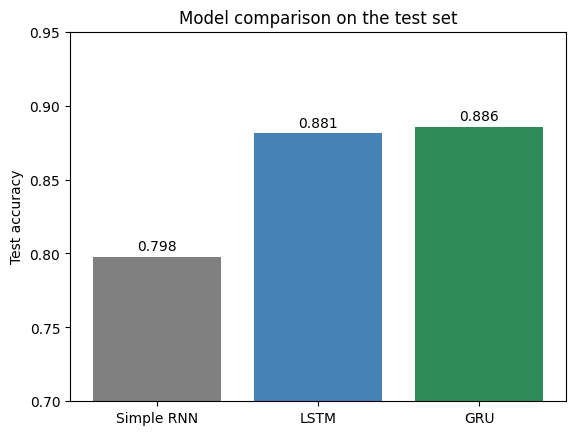

In [26]:
plt.bar(results_df['Model'], results_df['Test accuracy'], color=['gray', 'steelblue', 'seagreen'])
plt.ylim(0.7, 0.95)
plt.ylabel('Test accuracy')
plt.title('Model comparison on the test set')
for i, v in enumerate(results_df['Test accuracy']):
    plt.text(i, v + 0.004, f'{v:.3f}', ha='center')
plt.savefig(f'{BASE}/outputs/model_comparison.png')
plt.show()

              precision    recall  f1-score   support

    negative       0.89      0.87      0.88      3705
    positive       0.88      0.90      0.89      3733

    accuracy                           0.89      7438
   macro avg       0.89      0.89      0.89      7438
weighted avg       0.89      0.89      0.89      7438



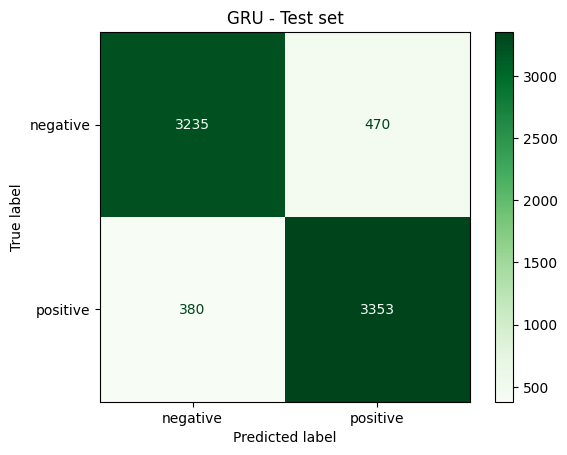

In [27]:
print(classification_report(labels, preds_by_model['GRU'], target_names=['negative', 'positive']))

ConfusionMatrixDisplay.from_predictions(
    labels, preds_by_model['GRU'], display_labels=['negative', 'positive'], cmap='Greens')
plt.title('GRU - Test set')
plt.savefig(f'{BASE}/outputs/gru_confusion.png')
plt.show()